In [79]:
import pickle
import json
import torch
import pandas as pd
import os

from post_analysis import parse_df_rules, plot_rule_importance, per_sample_rule_attribution

In [16]:
def load_pickle(filepath):
    with open(filepath, 'rb') as f:
        obj = pickle.load(f)
    return obj

def load_json(filepath):
    with open(filepath, 'rb') as f:
        obj = json.load(f)
    return obj

In [17]:
result_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/results.pkl"
rule_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/cv_fuzzy_rules.pkl"
param_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/cv_fuzzy_params.pkl"
meta_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/graph_meta.json"

result = load_pickle(result_path)
fuzzy_rule = load_pickle(rule_path)
fuzzy_params = load_pickle(param_path) 
meta = load_json(meta_path)

In [12]:
result['FuzzyGAT_direct_rules']['fuzzy_rules'][0].size()

torch.Size([691, 185])

In [15]:
result['FuzzyGAT_direct_rules']['fuzzy_params'][0]['theta'].size()

torch.Size([185])

In [34]:
patients = meta['patients']
rule_names = meta['rule_names']
direct_names = meta['direct_rule_names']
topo_names = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']

In [80]:
def parse_rule_activations(result_path:str, meta_path)->pd.DataFrame:
    # load result and meta
    with open(result_path, 'rb') as f:
        result = pickle.load(f)
    with open(meta_path, 'rb') as f:
        meta = json.load(f)
    
    patients = meta['patients']
    rule_names = meta['rule_names']
    direct_names = meta['direct_rule_names']
    topo_names = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']
    
    # extract rule_activations for all samples of all folds in one backbone model 
    rule_dfs = []
    for model_type, res in result.items():
        
        res_rules = res.get('fuzzy_rules')
        res_params = res.get('fuzzy_params')
        if isinstance(res_rules, list) and len(res_rules) !=0:
            for fold_idx, rules in enumerate(res_rules):
                if rules is None: # or not isinstance(rules, torch.Tensor):
                    continue
                
                # get rule activations 
                num_rules = rules.size(1)
                # print(rules.size())
                df = pd.DataFrame(rules)
                if num_rules == 5:
                    df.columns = topo_names
                elif num_rules == 185:
                    df.columns = direct_names
                elif num_rules == 190:
                    df.columns = topo_names + direct_names
                elif num_rules == 741:
                    df.columns = rule_names
                else:
                    df.columns = topo_names + rule_names
                df.insert(loc=0, column='sample_id', value=patients)
                df.insert(loc=1, column='model', value=model_type)
                df.insert(loc=2,column='fold',value=fold_idx+1)
            
                rule_dfs.append(df)

    df_rule_activation = pd.concat(rule_dfs, axis=0)
    return df_rule_activation

In [81]:
df_rule_activation = parse_rule_activations(result_path, meta_path)
df_rule_activation

,sample_id,model,fold,degrees,clustering,eigenvector_centrality,degree_centrality,avg_edge_weight,chain_SORL1_APP_CTL,chain_MME_APP_CTL,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,FuzzyGAT_topo,1,0.486002,0.453497,0.443283,0.487230,0.534404,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,FuzzyGAT_topo,1,0.486002,0.453497,0.552419,0.487230,0.522782,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,FuzzyGAT_topo,1,0.486002,0.612887,0.518729,0.487230,0.496951,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,FuzzyGAT_topo,1,0.486002,0.453497,0.511766,0.487230,0.509797,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,FuzzyGAT_topo,1,0.486002,0.852141,0.923173,0.487230,0.474953,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
686,TLSMCI607_1,FuzzyGAT_topo_all_rules,5,0.316269,0.958160,0.401628,0.311029,0.560138,0.521829,0.377177,...,0.661442,0.790492,0.791847,0.790900,0.773004,0.776043,0.776584,0.693239,0.689721,0.695230
687,TLSMCI608_1,FuzzyGAT_topo_all_rules,5,0.583623,0.822820,0.401628,0.585799,0.551748,0.828345,0.861510,...,0.744154,0.637433,0.638739,0.637270,0.719617,0.722084,0.723318,0.767542,0.763542,0.770160
688,TLSMCI609_1,FuzzyGAT_topo_all_rules,5,0.400969,0.615820,0.415537,0.397793,0.516177,0.277443,0.319474,...,0.182398,0.257534,0.257583,0.256115,0.219192,0.214446,0.219537,0.234992,0.237522,0.231631
689,TLSMCI611_1,FuzzyGAT_topo_all_rules,5,0.949043,0.350679,0.656403,0.953075,0.534103,0.355059,0.301944,...,0.323148,0.397670,0.398244,0.396529,0.359445,0.355915,0.361093,0.313437,0.315154,0.310604


In [82]:
# parse root folder to get all rule actiavtion for all backbone models
def parse_all_rule_activations(root_dir:str, output_dir:Optional[str]=None):
    activation_dfs = []
    for dirpath, _, filenames in os.walk(root_dir):
        
        # root_dir/dataset/k/backbone/results.pkl
        if 'results.pkl' not in filenames:
            continue
        result_path = os.path.join(dirpath,'results.pkl')

        # Calculate meta_path by going exactly one directory up from 'backbone' to 'k'
        parent_dir = os.path.dirname(dirpath)
        meta_path = os.path.join(parent_dir, 'graph_meta.json')
        
        # Safety check to ensure the meta file actually exists before processing
        if not os.path.exists(meta_path):
            print(f"Warning: Missing graph_meta.json for {result_path}. Skipping.")
            continue

        rel=os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        if len(parts) < 3:
            continue
        dataset=parts[0]
        k=parts[1]
        backbone=parts[2]

        df = parse_rule_activations(result_path, meta_path)
        df.insert(loc=3, column='dataset', value=dataset)
        df.insert(loc=4, column='k', value=k)
        df.insert(loc=5,column='backbone',value=backbone)
        activation_dfs.append(df)
    
    # Combine everything
    if activation_dfs:
        df_rule_activation = pd.concat(activation_dfs, axis=0, ignore_index=True)
    else:
        print("No valid result files found.")
        return pd.DataFrame()
        
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        df_rule_activation.to_csv(os.path.join(output_dir, 'df_samplewise_rule_activations.csv'))
    
    return df_rule_activation

In [83]:
root_dir= "../nesy_gnn/results/explain/AD_KG"
output_dir = "../nesy_gnn/results/explain/AD_KG/rules"
df_all_activation = parse_all_rule_activations(root_dir, output_dir)

df_all_activation

,sample_id,model,fold,dataset,k,backbone,degrees,clustering,eigenvector_centrality,degree_centrality,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.443283,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.552419,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.612887,0.518729,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.511766,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.852141,0.923173,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.332155,0.960963,0.419785,0.329545,...,0.683675,0.684229,0.682762,0.686348,0.686427,0.685961,0.724487,0.725035,0.725473,0.581494
69096,TLSMCI608_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.578092,0.828952,0.419785,0.580268,...,0.747017,0.747404,0.746337,0.839109,0.839582,0.838211,0.752516,0.753009,0.753426,0.833568
69097,TLSMCI609_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.410801,0.621224,0.432282,0.409620,...,0.262853,0.263923,0.261337,0.271425,0.270232,0.273024,0.356357,0.357228,0.357609,0.236438
69098,TLSMCI611_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.935808,0.351296,0.646809,0.939164,...,0.264917,0.265989,0.263397,0.303512,0.302356,0.305036,0.282792,0.283609,0.283923,0.320413


In [85]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

plot_df = df_all_activation[(df_all_activation['model']==model_type) &
                            (df_all_activation['dataset']==dataset) &
                            (df_all_activation['k'] == str(k))
                            ]

if 'sample_id' not in plot_df.columns and plot_df.index.name=='sample_id':
    plot_df.reset_index()
non_rule_cols = ['model', 'fold', 'dataset', 'k', 'backbone']
rule_cols = [col for col in plot_df.columns if col not in non_rule_cols]

plot_df = plot_df[rule_cols]

# melt
melted = plot_df.melt(id_vars='sample_id', var_name='rule_name', value_name='activation')
melted['occ'] = melted.groupby(['sample_id', 'rule_name']).cumcount()

new_df = melted.pivot(index=['rule_name','occ'], columns='sample_id', values='activation').reset_index()
new_df = new_df.drop(columns=['occ']).dropna()
new_df

sample_id,rule_name,DCR00001_1,DCR00004_1,DCR00009_1,DCR00013_1,DCR00014_1,DCR00015_1,DCR00018_1,DCR00020_1,DCR00021_1,...,TLSMCI602_1,TLSMCI603_1,TLSMCI604_1,TLSMCI605_1,TLSMCI606_1,TLSMCI607_1,TLSMCI608_1,TLSMCI609_1,TLSMCI611_1,TLSMCI612_1
30,chain_ABCA1_APP_CTL,0.330015,0.232276,0.326245,0.165914,0.389931,0.435265,0.288961,0.270556,0.400005,...,0.685581,0.652266,0.822159,0.654485,0.645820,0.483950,0.704445,0.585410,0.137727,0.727822
31,chain_ABCA1_APP_CTL,0.330889,0.234337,0.327172,0.168427,0.389907,0.434524,0.290389,0.272209,0.399822,...,0.681431,0.648436,0.817600,0.650631,0.642059,0.482436,0.700145,0.582391,0.140295,0.723370
32,chain_ABCA1_APP_CTL,0.327752,0.230303,0.323988,0.164286,0.387601,0.432935,0.286791,0.268441,0.397671,...,0.683921,0.650461,0.821222,0.652689,0.643988,0.481667,0.702873,0.583360,0.136285,0.726365
33,chain_ABCA1_APP_CTL,0.335743,0.238396,0.332003,0.171678,0.395034,0.439754,0.294963,0.276633,0.404980,...,0.685733,0.653002,0.820403,0.655181,0.646671,0.487681,0.704280,0.587358,0.143132,0.727280
34,chain_ABCA1_APP_CTL,0.320109,0.224469,0.316404,0.159971,0.379137,0.424009,0.279840,0.261833,0.389092,...,0.675198,0.641419,0.814872,0.643665,0.634896,0.472403,0.694374,0.573961,0.132677,0.718189
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3675,direct_XBP1_AD,0.257831,0.383368,0.411418,0.331087,0.220133,0.228104,0.298183,0.316286,0.332635,...,0.683323,0.627894,0.709220,0.807022,0.765644,0.705698,0.555444,0.279739,0.339271,0.641022
3676,direct_XBP1_AD,0.256427,0.383996,0.412551,0.330807,0.218264,0.226325,0.297370,0.315762,0.332382,...,0.688506,0.632516,0.714586,0.812482,0.771194,0.711043,0.559062,0.278646,0.339130,0.645795
3677,direct_XBP1_AD,0.255497,0.380493,0.408475,0.328391,0.218036,0.225955,0.295633,0.313652,0.329933,...,0.680707,0.625066,0.706728,0.805147,0.763479,0.703188,0.552451,0.277283,0.336543,0.638237
3678,direct_XBP1_AD,0.258552,0.383811,0.411781,0.331666,0.220895,0.228860,0.298834,0.316899,0.333211,...,0.682855,0.627576,0.708692,0.806351,0.765015,0.705178,0.555349,0.280425,0.339831,0.640666


In [63]:
from typing import Optional
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_rule_importance(df: pd.DataFrame, x_col: str, y_col: str, 
                         title: Optional[str] = None,
                         cmap='coolwarm',
                         central_vertical_line:float=0.0,
                         interpolate: bool = True, 
                         save_path: Optional[str] = None) -> pd.DataFrame:
    """
    Plots a SHAP-style summary scatter plot of rule importances.

    Args:
        df (pd.DataFrame): The dataframe containing the attribution values.
        x_col (str): The column name representing the X-axis (Importance values).
        y_col (str): The column name representing the Y-axis (e.g., 'rule_name').
        title (Optional[str]): Custom title for the plot. Defaults to None.
        interpolate (bool): If True, simulates more data points by duplicating 
                            rows and adding Gaussian noise. Defaults to True.
        save_path (Optional[str]): If provided, saves the figure to this file path.

    Returns:
        pd.DataFrame: A copy of the processed dataframe with calculated y-positions.
    """
    plot_df = df.copy()
    color_col = x_col

    if interpolate:
        # 1. Duplicate and add noise to simulate having multiple points per rule
        plot_df = pd.concat([plot_df] * 20, ignore_index=True)
        plot_df[x_col] += np.random.normal(0, 0.001, len(plot_df))

    # 2. Sort rules by their mean importance so the most important is at the top
    # Double brackets [[x_col]] and by=x_col safely prevents DataFrame sorting errors
    mean_importance = plot_df.groupby(y_col)[[x_col]].mean()
    order = mean_importance.sort_values(by=x_col, ascending=False).index
    
    y_mapping = {rule: i for i, rule in enumerate(order)}
    plot_df['y_pos'] = plot_df[y_col].map(y_mapping)
    
    # print top-5 importance rules names
    top_rules = order[:5].tolist()
    print(f"Top-5 {y_col} by {x_col}:\n{top_rules}")

    # 3. Create the plot
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Add a slight vertical jitter so points don't heavily overlap
    jitter = np.random.normal(0, 0.05, size=len(plot_df))

    # Scatter plot using a colormap
    sc = ax.scatter(
        plot_df[x_col], 
        plot_df['y_pos'] + jitter, 
        c=plot_df[color_col], 
        cmap=cmap, # blue-pink-red
        s=15, 
        alpha=0.8,
        edgecolors='none'
    )

    # 4. Formatting
    # Set Y-axis labels to the rule names
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=8)
    ax.invert_yaxis() # Puts the most important rule at the top

    # Add the central vertical line at 0
    ax.axvline(central_vertical_line, color='grey', linestyle='-', linewidth=1.5, alpha=0.5)

    # Style the axes
    ax.set_xlabel(x_col, fontsize=12)
    if title:
        ax.set_title(title, fontsize=14, pad=15)
        
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)
    sns.despine(left=True, bottom=False)
    ax.tick_params(axis='y', length=0) # Remove y-axis tick marks for a cleaner look

    # 5. Add and format the colorbar
    cbar = plt.colorbar(sc, ax=ax, aspect=40, pad=0.05)
    cbar.set_label('Feature Value', fontsize=10)
    cbar.set_ticks([plot_df[color_col].min(), plot_df[color_col].max()])
    cbar.set_ticklabels(['Low', 'High'])
    cbar.ax.set_frame_on(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved plot to {save_path}")
    plt.show()

    return plot_df

Top-5 rule_name by DCR00001_1:
['direct_TNFRSF1B_CTL', 'chain_MMP9_APP_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_SNCA_MAPT_AD', 'direct_IRS2_CTL']


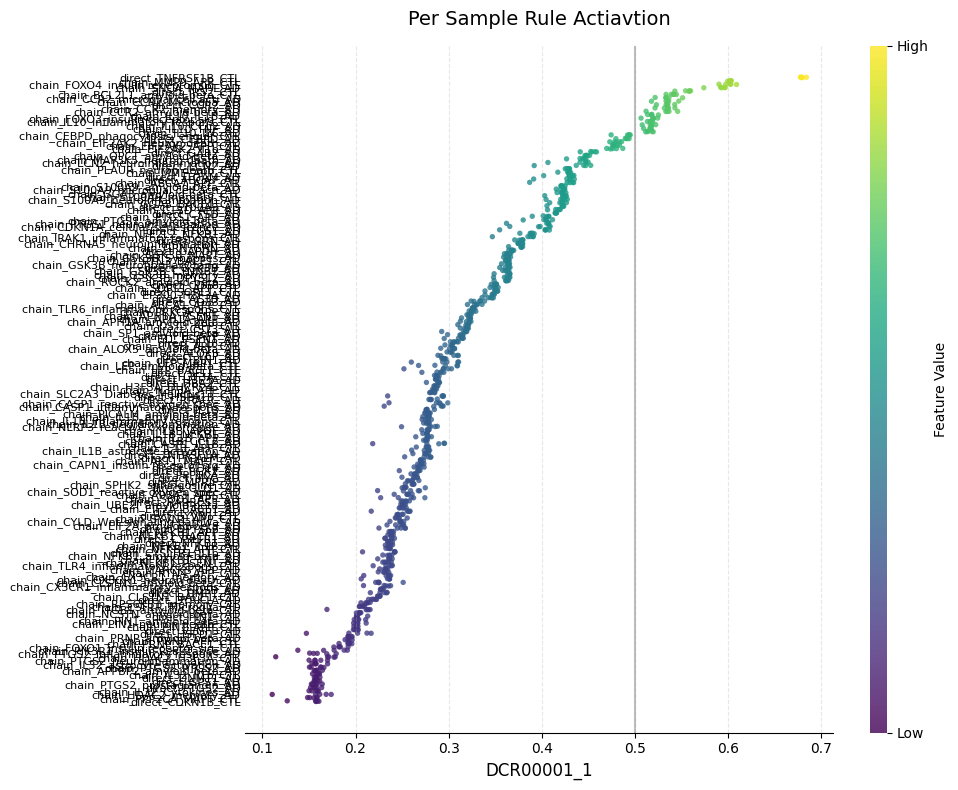

In [65]:
df_plot = plot_rule_importance(df=new_df,
                            x_col='DCR00001_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            save_path = False)

In [69]:
df_plot

sample_id,rule_name,DCR00001_1,DCR00004_1,DCR00009_1,DCR00013_1,DCR00014_1,DCR00015_1,DCR00018_1,DCR00020_1,DCR00021_1,...,TLSMCI603_1,TLSMCI604_1,TLSMCI605_1,TLSMCI606_1,TLSMCI607_1,TLSMCI608_1,TLSMCI609_1,TLSMCI611_1,TLSMCI612_1,y_pos
30,chain_ABCA1_APP_CTL,0.330015,0.232276,0.326245,0.165914,0.389931,0.435265,0.288961,0.270556,0.400005,...,0.652266,0.822159,0.654485,0.645820,0.483950,0.704445,0.585410,0.137727,0.727822,67
31,chain_ABCA1_APP_CTL,0.330889,0.234337,0.327172,0.168427,0.389907,0.434524,0.290389,0.272209,0.399822,...,0.648436,0.817600,0.650631,0.642059,0.482436,0.700145,0.582391,0.140295,0.723370,67
32,chain_ABCA1_APP_CTL,0.327752,0.230303,0.323988,0.164286,0.387601,0.432935,0.286791,0.268441,0.397671,...,0.650461,0.821222,0.652689,0.643988,0.481667,0.702873,0.583360,0.136285,0.726365,67
33,chain_ABCA1_APP_CTL,0.335743,0.238396,0.332003,0.171678,0.395034,0.439754,0.294963,0.276633,0.404980,...,0.653002,0.820403,0.655181,0.646671,0.487681,0.704280,0.587358,0.143132,0.727280,67
34,chain_ABCA1_APP_CTL,0.320109,0.224469,0.316404,0.159971,0.379137,0.424009,0.279840,0.261833,0.389092,...,0.641419,0.814872,0.643665,0.634896,0.472403,0.694374,0.573961,0.132677,0.718189,67
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3675,direct_XBP1_AD,0.257831,0.383368,0.411418,0.331087,0.220133,0.228104,0.298183,0.316286,0.332635,...,0.627894,0.709220,0.807022,0.765644,0.705698,0.555444,0.279739,0.339271,0.641022,128
3676,direct_XBP1_AD,0.256427,0.383996,0.412551,0.330807,0.218264,0.226325,0.297370,0.315762,0.332382,...,0.632516,0.714586,0.812482,0.771194,0.711043,0.559062,0.278646,0.339130,0.645795,128
3677,direct_XBP1_AD,0.255497,0.380493,0.408475,0.328391,0.218036,0.225955,0.295633,0.313652,0.329933,...,0.625066,0.706728,0.805147,0.763479,0.703188,0.552451,0.277283,0.336543,0.638237,128
3678,direct_XBP1_AD,0.258552,0.383811,0.411781,0.331666,0.220895,0.228860,0.298834,0.316899,0.333211,...,0.627576,0.708692,0.806351,0.765015,0.705178,0.555349,0.280425,0.339831,0.640666,128


In [72]:
df_sample1 = df_plot[df_plot['DCR00001_1']>0.5]
df_sample1 = df_sample1.sort_values(by='DCR00001_1', ascending=False)
df_sample1

sample_id,rule_name,DCR00001_1,DCR00004_1,DCR00009_1,DCR00013_1,DCR00014_1,DCR00015_1,DCR00018_1,DCR00020_1,DCR00021_1,...,TLSMCI603_1,TLSMCI604_1,TLSMCI605_1,TLSMCI606_1,TLSMCI607_1,TLSMCI608_1,TLSMCI609_1,TLSMCI611_1,TLSMCI612_1,y_pos
3669,direct_TNFRSF1B_CTL,0.683878,0.738169,0.700033,0.600897,0.686905,0.726014,0.680025,0.637449,0.628325,...,0.342735,0.350575,0.416769,0.214003,0.097447,0.326586,0.699218,0.753616,0.418347,0
3668,direct_TNFRSF1B_CTL,0.679468,0.731286,0.694839,0.600946,0.682345,0.719642,0.675807,0.635464,0.626840,...,0.356435,0.363961,0.427114,0.230782,0.111405,0.340897,0.694063,0.746125,0.428613,0
3667,direct_TNFRSF1B_CTL,0.678756,0.730628,0.694141,0.600187,0.681636,0.718970,0.675092,0.634720,0.626091,...,0.355778,0.363296,0.426391,0.230306,0.111165,0.340258,0.693364,0.745487,0.427889,0
3665,direct_TNFRSF1B_CTL,0.678379,0.730609,0.693873,0.599235,0.681279,0.718873,0.674688,0.634022,0.625330,...,0.353374,0.360919,0.424299,0.227745,0.109184,0.337804,0.693090,0.745564,0.425804,0
3666,direct_TNFRSF1B_CTL,0.677438,0.729219,0.692790,0.599103,0.680311,0.717576,0.673783,0.633522,0.624920,...,0.355763,0.363247,0.426052,0.230779,0.111814,0.340311,0.692015,0.744063,0.427542,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489,chain_CCR2_amyloid-beta_AD,0.511800,0.704711,0.636287,0.526526,0.032086,0.393647,0.625705,0.511851,0.671009,...,0.146135,0.741024,0.813357,0.713839,0.489523,0.499477,0.127957,0.155311,0.271460,10
1626,chain_IL10_IL6_AD,0.511430,0.532076,0.759955,0.325799,0.121350,0.242487,0.139387,0.605078,0.191373,...,0.791508,0.801183,0.707734,0.547672,0.177146,0.544806,0.394735,0.484544,0.494279,16
1634,chain_IL10_TNF_AD,0.509153,0.532410,0.782988,0.302791,0.095802,0.214514,0.112514,0.614364,0.162722,...,0.815736,0.825625,0.727360,0.549969,0.148708,0.546743,0.378397,0.478875,0.489834,15
1619,chain_IL10_CCL2_AD,0.507681,0.532415,0.795153,0.290058,0.083537,0.199666,0.099356,0.619399,0.148031,...,0.828324,0.838249,0.737931,0.551083,0.134290,0.547654,0.369114,0.475491,0.487139,14


In [73]:
df_sample1['rule_name'].unique()

<StringArray>
[                 'direct_TNFRSF1B_CTL',
 'chain_FOXO4_insulin receptor sig_CTL',
                   'chain_MMP9_APP_CTL',
                   'chain_SNCA_MAPT_AD',
                      'direct_IRS2_CTL',
   'chain_CCR2_microglial cell acti_AD',
              'chain_CCR2_Microglia_AD',
           'chain_CCR2_amyloid-beta_AD',
        'chain_BCL2L1_amyloid-beta_CTL',
                 'chain_CCR2_memory_AD',
                       'direct_CCR2_AD',
                   'chain_IL10_IL1B_AD',
 'chain_FOXO3_insulin receptor sig_CTL',
                   'chain_IL10_CCL2_AD',
                    'chain_IL10_IL6_AD',
  'chain_IL10_inflammatory respons_CTL',
                    'chain_IL10_TNF_AD']
Length: 17, dtype: str